[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/FBE5d5wqfds/EAIF-/blob/main/practical_lungs/L1_P4_lung_images_underwriting_solution.ipynb)


# Lecture 1 · Practical 4 — Images: when a table of pixels is the wrong representation
### Smoking status from chest images in supplementary-insurance underwriting: a convolutional network against gradient boosting on pixel intensities

**Version: instructor solution**

### Where this notebook sits in Lecture 1
The lecture showed a convolutional network (CNN) that reads hand-written digits on cheques (LeCun et al., 1998). Gradient boosting could also read such images: we would write every image as one row of a table, with one column per pixel intensity. This practical tests that idea on a health-insurance question and explains, with controlled experiments, **why** the table of pixels serves gradient boosting badly and what a CNN does differently.

> **The business question.** In Switzerland, basic health insurance (OKP/LAMal) must accept everybody. Supplementary insurance (VVG/LCA), such as a private hospital ward or alternative medicine, does not: the insurer may decline an applicant, exclude a pre-existing condition, or ask for a health questionnaire and, sometimes, medical tests. The applicant must answer the questionnaire truthfully (duty of disclosure, Art. 4 VVG). Smoking strongly raises the risk of lung disease, heart disease and cancer, so underwriters ask about it. Older applicants and applicants with a history of disease often pass through this stricter route.
>
> **The modelling question.** Suppose an underwriter holds a recent chest radiograph of an applicant, taken for a medical reason and shared with the applicant's consent. Can a model read from the image whether the applicant **never smoked**, **stopped within the last five years**, or **smokes now**? And which kind of model can learn this from very few images?

We read the three annotation classes as follows: *never* = never smoked; *former* = stopped smoking within the last five years; *current* = smokes now (has never stopped).

### Learning goals
1. Represent an image in two ways, as a **table of pixel intensities** and as a **grid** for a convolutional network, and train gradient boosting and a CNN on 60 images.
2. Split a tiny data set in a **balanced** way and report metrics that remain meaningful with 18 test images: accuracy, macro-F1, recall per class, confusion matrix, log-loss and AUC, **repeated over several splits**.
3. Explain the result with controlled experiments: the **average image** of each class, **implanting** lesions into healthy images, and **shifting** images by a few pixels.
4. Test the remark that boosting becomes competitive with **engineered features**, and discuss what that requires.
5. Judge whether an insurer **may** use such a model under Swiss data-protection and insurance rules.

**About the data.** The 60 images are **synthetic** and far from real radiographs (Section 1 lists every mechanism). They mimic one documented finding: smokers' radiographs show more lung markings, a "dirty chest", and the amount grows with tobacco exposure (Kirchner et al., 2012). Real models that read chest radiographs exist: Lu et al. (2020) trained a CNN on chest radiographs to identify smokers at high risk of lung cancer. The point of this practical is the **comparison of model families** on image data, not a usable diagnostic tool.

Runtime: about 12 minutes on a 2-core CPU (Section 5 trains 20 networks); proportionally less with more cores.

In [1]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from scipy import ndimage as ndi
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, log_loss, roc_auc_score, confusion_matrix

SEED = 2026
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
pd.set_option("display.precision", 3); pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLASSES = ["never", "former", "current"]
NAMES = {"never": "never smoked", "former": "quit < 5 years ago", "current": "smokes now"}
COL = {"never": "#1A3F99", "former": "#FAC300", "current": "#C8553D"}

## 1 · The images
The folder `data/lung_xray/` holds 60 grey-scale images of 64 × 64 pixels (`chest_001.png` … `chest_060.png`) and a table `annotations.csv` with the smoking status of each image: 20 per class. If the folder is missing, the next cell regenerates it with `lung_images.py`.

In [2]:
FOLDER = Path("data/lung_xray")
if not (FOLDER / "annotations.csv").exists():
    import lung_images; lung_images.save_dataset(FOLDER)
ann = pd.read_csv(FOLDER / "annotations.csv")
X = np.stack([np.asarray(Image.open(FOLDER / f), dtype=np.float32) / 255 for f in ann.file])   # intensities between 0 and 1
y = ann.smoking_status.map({c: k for k, c in enumerate(CLASSES)}).values
print("images:", X.shape, "· intensity range:", X.min().round(2), "to", X.max().round(2))
print(ann.smoking_status.value_counts().reindex(CLASSES).to_string())
ann.head()

images: (60, 64, 64) · intensity range: 0.04 to 1.0
smoking_status
never      20
former     20
current    20


,image_id,file,smoking_status,description
0,chest_001,chest_001.png,never,never smoked
1,chest_002,chest_002.png,current,current smoker
2,chest_003,chest_003.png,current,current smoker
3,chest_004,chest_004.png,never,never smoked
4,chest_005,chest_005.png,former,"former smoker, quit within the last 5 years"


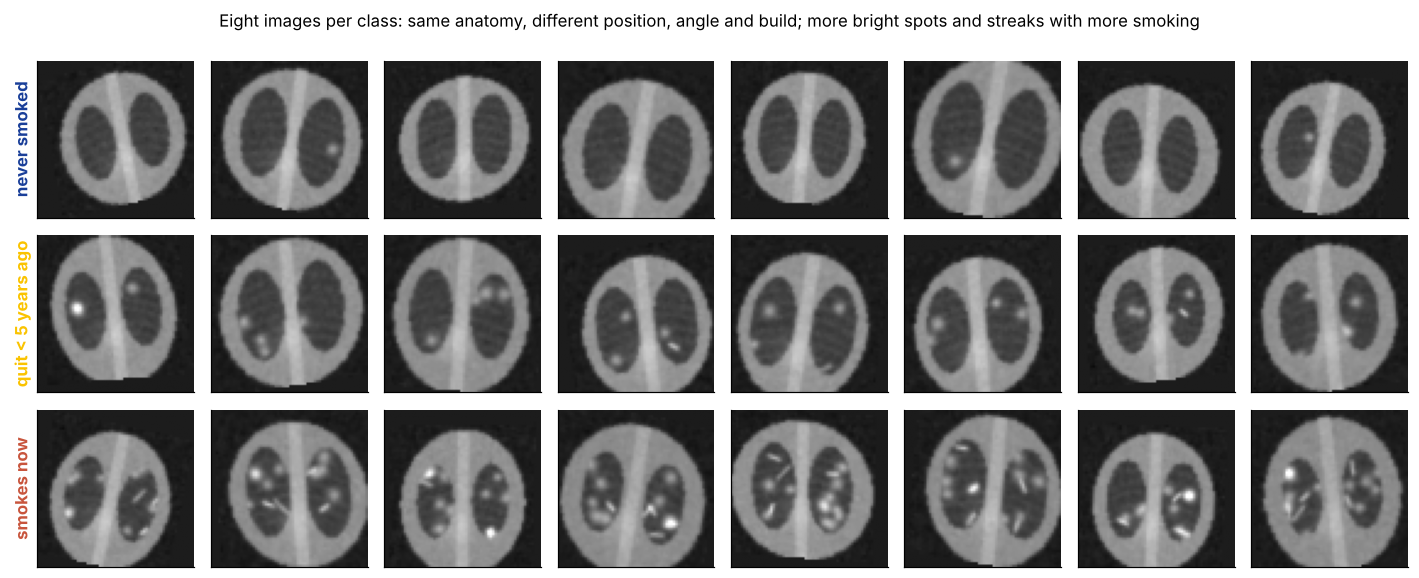

In [3]:
fig, axs = plt.subplots(3, 8, figsize=(13, 5.4))
for r, c in enumerate(CLASSES):
    for j, i in enumerate(np.where(y == r)[0][:8]):
        axs[r, j].imshow(X[i], cmap="gray", vmin=0, vmax=1); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
        if j == 0: axs[r, j].set_ylabel(NAMES[c], fontsize=11, color=COL[c], fontweight="bold")
fig.suptitle("Eight images per class: same anatomy, different position, angle and build; more bright spots and streaks with more smoking", fontsize=11)
plt.tight_layout(); plt.show()

### 1.1 · What is in an image
The generator `lung_images.py` builds every image from the following mechanisms. Only the last one depends on the class.

| mechanism | what it does | depends on the class? |
|---|---|---|
| anatomy | dark air around a bright body; two dark lungs; heart shadow, spine and six faint ribs | no |
| build | lungs slightly larger or smaller (±10%) | no |
| position and perspective | rotation (±12°), scale (±10%), shear (±0.08, a crude change of viewing angle) and shift (±4 pixels) | no |
| exposure and noise | brightness and contrast vary; sensor noise; slight blur. Every image is then rescaled so that air and soft tissue have the same grey level | no |
| **lung markings** | small bright **nodules** and thin **streaks** at **random positions inside the lungs**: never smoked 0–1 nodules; quit < 5 years 3–5 nodules and up to 1 streak; smokes now 8–12 nodules and 3–5 streaks | **yes** |

Two facts matter for the comparison. First, the class lives in **local patterns** of a few pixels. Second, these patterns appear at a **different place** in every image, and the whole chest also moves from image to image.

### 1.2 · The average image of each class
A model that treats each pixel as a separate column can only use differences that sit **at the same pixel** across images. The class averages show how much of the class signal survives this view.

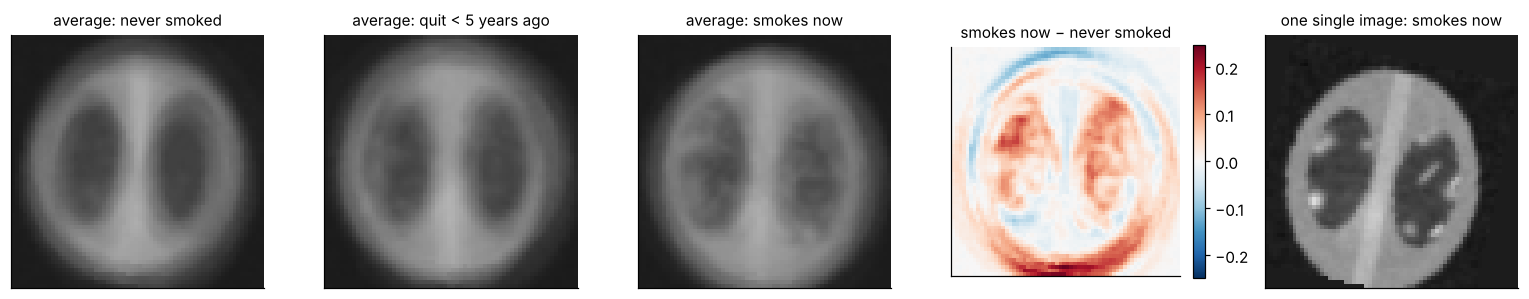

pixels where the difference between the two averages exceeds the spread within a class: 173 of 4,096


In [4]:
means = np.stack([X[y == k].mean(0) for k in range(3)])
fig, axs = plt.subplots(1, 5, figsize=(14, 3.2))
for k, c in enumerate(CLASSES):
    axs[k].imshow(means[k], cmap="gray", vmin=0, vmax=1); axs[k].set_title(f"average: {NAMES[c]}", fontsize=10)
d = means[2] - means[0]; v = np.abs(d).max()
im = axs[3].imshow(d, cmap="RdBu_r", vmin=-v, vmax=v); axs[3].set_title("smokes now − never smoked", fontsize=10); plt.colorbar(im, ax=axs[3], fraction=0.046)
axs[4].imshow(X[np.where(y == 2)[0][0]], cmap="gray", vmin=0, vmax=1); axs[4].set_title("one single image: smokes now", fontsize=10)
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
sd_within = np.sqrt((X[y == 2].var(0) + X[y == 0].var(0)) / 2)
print(f"pixels where the difference between the two averages exceeds the spread within a class: {(np.abs(d) > sd_within).sum()} of 4,096")

The three averages look alike: a blurred chest, because every image sits at a slightly different place and angle. The nodules of a smoker also sit at random places, so averaging spreads them into a **diffuse haze**: the lungs of smokers are, on average, slightly brighter (red areas in the difference map). The blue and red bands along the body outline have another cause: with 20 images per class, the random positions of the chests do not average out exactly, so the outline sits a little differently in each class by chance.

For only about 4% of the pixels does the difference between the class averages exceed the spread of that pixel within a class. **Per pixel, the classes differ weakly and diffusely; per image, they differ clearly** (compare the single image on the right). A model that reads pixels as separate columns can therefore use two things: a weak signal (lung brightness) and a spurious one (chance differences in position). It cannot use the spots themselves. This observation predicts the results of the notebook.

## 2 · A balanced split
With 60 images we keep 14 images per class for training (42) and 6 per class for testing (18). A *stratified* split guarantees these proportions.

### ✏️ Exercise 1 — balanced split
Create the index arrays `tr` and `te` with `train_test_split`, 18 test images, stratified by `y`, `random_state=SEED`, and print the number of images per class in each part.

In [5]:
# ✅ SOLUTION
idx = np.arange(len(y))
tr, te = train_test_split(idx, test_size=18, stratify=y, random_state=SEED)
print("train:", np.bincount(y[tr]), "· test:", np.bincount(y[te]))

train: [14 14 14] · test: [6 6 6]


### 2.1 · Metrics
Six test images per class make every metric noisy, so we report several and later repeat the whole experiment over ten different splits.

* **accuracy:** share of images classified correctly; chance level is 1/3. With 18 test images, one image moves accuracy by 5.6 percentage points.
* **macro-F1:** the F1 score (harmonic mean of precision and recall) of each class, averaged with equal weight; with balanced classes it stays close to accuracy but penalises a model that ignores one class.
* **recall per class:** for underwriting, the important errors differ by class. A **current smoker classified as never smoked** means an under-priced risk; a **never-smoker classified as current smoker** means an unfair extra questionnaire or a refusal.
* **log-loss** (cross-entropy, Lecture 1): penalises confident wrong probabilities; a model that always says 1/3 scores ln 3 ≈ 1.10.
* **AUC (one class against the rest, averaged):** whether the model **ranks** images of a class above the others, independent of any threshold; 0.5 is chance.

### ✏️ Exercise 2 — metric report
Write `report(name, y_true, P)` that receives the predicted probabilities `P` (one row per image, one column per class) and returns a dictionary with all of the metrics above. Clip probabilities to at least 1e-6 and renormalise before the log-loss.

In [6]:
# ✅ SOLUTION
def report(name, y_true, P):
    P = np.clip(P, 1e-6, 1); P = P / P.sum(1, keepdims=True); pred = P.argmax(1)
    rec = recall_score(y_true, pred, labels=[0, 1, 2], average=None, zero_division=0)
    return dict(model=name, accuracy=accuracy_score(y_true, pred), macro_F1=f1_score(y_true, pred, average="macro"),
                recall_never=rec[0], recall_former=rec[1], recall_current=rec[2],
                log_loss=log_loss(y_true, P, labels=[0, 1, 2]), AUC=roc_auc_score(y_true, P, multi_class="ovr"))

In [7]:
main = []          # results on the main split
probs = {}         # predicted probabilities on the main test images, per model
def show_confusions(models):
    fig, axs = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.6))
    for a, m in zip(np.atleast_1d(axs), models):
        cm = confusion_matrix(y[te], probs[m].argmax(1), labels=[0, 1, 2])
        a.imshow(cm, cmap="Blues", vmin=0, vmax=6)
        for i in range(3):
            for j in range(3): a.text(j, i, cm[i, j], ha="center", va="center", fontsize=13, color="white" if cm[i, j] > 3 else "black")
        a.set_xticks(range(3), [NAMES[c] for c in CLASSES], rotation=20, fontsize=8); a.set_yticks(range(3), [NAMES[c] for c in CLASSES], fontsize=8)
        a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(m, fontsize=10)
    plt.tight_layout(); plt.show()

## 3 · Gradient boosting on pixel intensities
We flatten every 64 × 64 image into one row of **4,096 columns**, one per pixel intensity, exactly as a tabular data set: column 1 is the top-left pixel, column 4,096 the bottom-right pixel. Gradient boosting then builds shallow trees, each of which splits on single pixels ("is pixel 1,873 brighter than 0.41?").

### ✏️ Exercise 3 — boosting on pixels
Fit `gb_pixels()` on the flattened training images, predict probabilities for the test images, store them in `probs["boosting · 4,096 pixels"]` and append `report(...)` to `main`.

In [8]:
def flat(X): return X.reshape(len(X), -1)
def gb_pixels(seed=SEED): return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, max_depth=3, random_state=seed)

In [9]:
# ✅ SOLUTION
t0 = time.time()
gb = gb_pixels().fit(flat(X[tr]), y[tr])
probs["boosting · 4,096 pixels"] = gb.predict_proba(flat(X[te]))
main.append(report("boosting · 4,096 pixels", y[te], probs["boosting · 4,096 pixels"]))
print(f"({time.time() - t0:.1f} s)"); pd.DataFrame(main).set_index("model")

(2.4 s)


,accuracy,macro_F1,recall_never,recall_former,recall_current,log_loss,AUC
model,,,,,,,
"boosting · 4,096 pixels",0.556,0.531,0.833,0.167,0.667,1.576,0.792


### 3.1 · Which pixels do the trees use?
Every split of every tree uses one pixel. We add up the improvement in the loss (the *gain*) that each pixel brings over all trees and draw it as a 64 × 64 map. (`_predictors` is an internal attribute of scikit-learn's implementation; it holds the trees.)

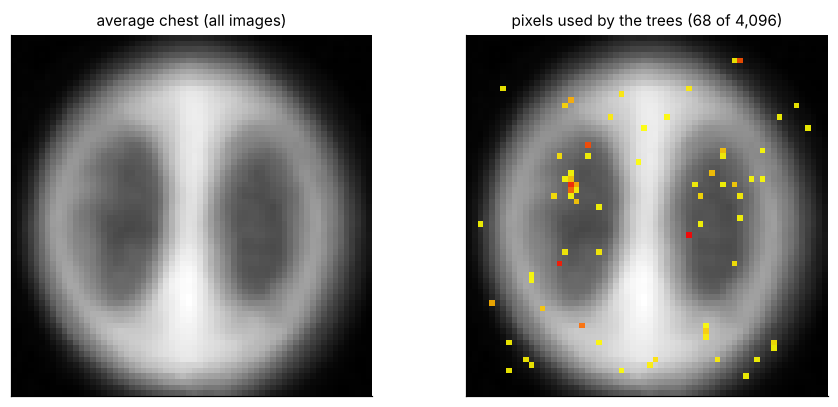

In [10]:
def gain_map(model):
    g = np.zeros(64 * 64)
    for it in model._predictors:
        for tree in it:
            n = tree.nodes[~tree.nodes["is_leaf"].astype(bool)]
            np.add.at(g, n["feature_idx"], n["gain"])
    return g.reshape(64, 64)
G = gain_map(gb)
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.8))
axs[0].imshow(means.mean(0), cmap="gray"); axs[0].set_title("average chest (all images)", fontsize=10)
axs[1].imshow(means.mean(0), cmap="gray"); axs[1].imshow(np.ma.masked_equal(G, 0), cmap="autumn_r", alpha=.9)
axs[1].set_title(f"pixels used by the trees ({(G > 0).sum()} of 4,096)", fontsize=10)
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The trees rely on a few dozen scattered pixels. Some lie inside the lungs, where smokers' images are brighter on average (Section 1.2); others lie on the body outline or even in the air around the body, where only chance differences in position separate the classes among 42 training images. With 4,096 columns and 42 rows, many pixels separate the training images by coincidence. The trees learn **brightness at fixed positions**, not the pattern "bright spot inside a dark lung"; Section 6 tests this directly.

## 4 · A convolutional network on the image grid
A CNN keeps the image as a grid and applies the same small filters at every position (Lecture 1, *Architecture*):

* **convolution:** each 3 × 3 filter computes a weighted sum of a pixel and its eight neighbours and slides over the whole image, so one filter detects "a bright spot surrounded by dark" **wherever** it occurs (weight sharing, translation equivariance);
* **batch normalisation** rescales each filter's output inside a batch, which stabilises training (Ioffe & Szegedy, 2015);
* **max-pooling** halves the resolution, so later filters see larger regions;
* **global average pooling** averages each filter's map over the whole image: the result measures **how much** of a pattern the image contains, independent of **where** (Lin et al., 2014). For our task this amounts to counting lesions;
* a final linear layer with softmax turns the 32 averages into three class probabilities.

**Data augmentation.** With 42 training images the network would memorise them. At every step we therefore show it randomly rotated (±15°), shifted (±10%), rescaled (±10%) and mirrored versions of the training images. Augmentation states our prior knowledge explicitly: the position and angle of the chest do not change the smoking status (Shorten & Khoshgoftaar, 2019).

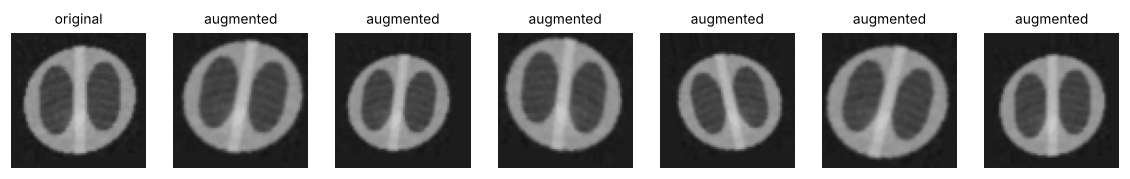

In [11]:
def augment(xb, g):
    """Random rotation, shift, scale and horizontal flip of a batch (B, 1, 64, 64)."""
    B = xb.shape[0]; u = lambda: torch.rand(B, generator=g) - 0.5
    ang, sc = u() * 2 * np.deg2rad(15), 1 + u() * 0.2
    flip = torch.where(torch.rand(B, generator=g) < 0.5, -1.0, 1.0)
    th = torch.zeros(B, 2, 3)
    th[:, 0, 0], th[:, 0, 1] = flip * torch.cos(ang) / sc, -torch.sin(ang) / sc
    th[:, 1, 0], th[:, 1, 1] = flip * torch.sin(ang) / sc, torch.cos(ang) / sc
    th[:, 0, 2], th[:, 1, 2] = u() * 0.2, u() * 0.2
    grid = F.affine_grid(th, xb.shape, align_corners=False)
    return F.grid_sample(xb, grid, align_corners=False, padding_mode="border")

g = torch.Generator().manual_seed(SEED); demo = augment(torch.tensor(X[tr[:1]][:, None]).repeat(6, 1, 1, 1), g)
fig, axs = plt.subplots(1, 7, figsize=(13, 2.2))
axs[0].imshow(X[tr[0]], cmap="gray", vmin=0, vmax=1); axs[0].set_title("original", fontsize=9)
for a, im in zip(axs[1:], demo): a.imshow(im[0], cmap="gray", vmin=0, vmax=1); a.set_title("augmented", fontsize=9)
for a in axs: a.axis("off")
plt.show()

### ✏️ Exercise 4 — the network
Complete `LungCNN`: three blocks *convolution 3 × 3 (padding 1) → batch normalisation → ReLU* with 16, 32 and 32 filters, a 2 × 2 max-pooling after the first and the second block, global average pooling, dropout 0.3 and a linear layer to 3 classes. Keep the names `features` (the three blocks), `pool` and `head`: Section 6 uses them.

In [12]:
# ✅ SOLUTION
class LungCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        def block(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU()]
        self.features = nn.Sequential(*block(1, 16), nn.MaxPool2d(2), *block(16, 32), nn.MaxPool2d(2), *block(32, 32))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(32, n_classes))
    def forward(self, x): return self.head(self.pool(self.features(x)))

parameters: 14307 (boosting on pixels: 4,096 input columns)


(22 s)


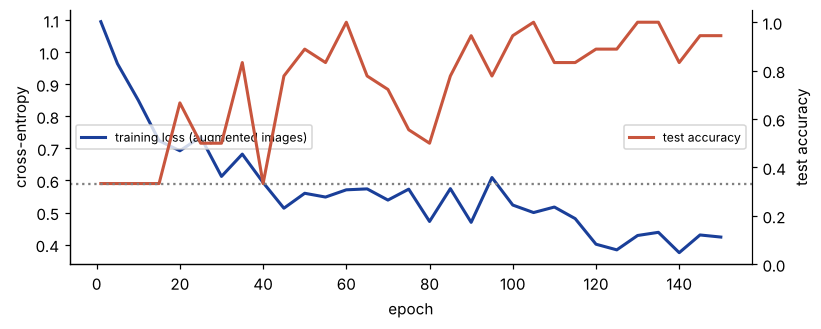

,accuracy,macro_F1,recall_never,recall_former,recall_current,log_loss,AUC
model,,,,,,,
"boosting · 4,096 pixels",0.556,0.531,0.833,0.167,0.667,1.576,0.792
CNN,0.944,0.944,1.000,0.833,1.000,0.349,1.000


In [13]:
def fit_cnn(Xtr, ytr, seed=SEED, epochs=150, batch=8, lr=2e-3, use_aug=True, Xval=None, yval=None):
    """Adam with a cosine learning-rate schedule; mini-batches of 8 images; returns the model and a training history."""
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    model = LungCNN(); opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(ytr) / batch)); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    xt, yt = torch.tensor(Xtr[:, None]), torch.tensor(ytr); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(yt), generator=g); tot = 0
        for i in range(0, len(yt), batch):
            b = perm[i:i + batch]
            if len(b) < 2: continue                       # batch normalisation needs at least two images
            xb = augment(xt[b], g) if use_aug else xt[b]
            loss = F.cross_entropy(model(xb), yt[b]); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(b)
        if Xval is not None and (ep % 5 == 4 or ep == 0):
            hist.append(dict(epoch=ep + 1, train_loss=tot / len(yt), test_accuracy=accuracy_score(yval, predict_cnn(model, Xval).argmax(1))))
    model.eval(); return model, pd.DataFrame(hist)

def predict_cnn(model, X):
    model.eval()
    with torch.no_grad(): return F.softmax(model(torch.tensor(X[:, None])), 1).numpy()

print("parameters:", sum(p.numel() for p in LungCNN().parameters()), "(boosting on pixels: 4,096 input columns)")
t0 = time.time()
cnn, hist = fit_cnn(X[tr], y[tr], Xval=X[te], yval=y[te])
probs["CNN"] = predict_cnn(cnn, X[te]); main.append(report("CNN", y[te], probs["CNN"]))
print(f"({time.time() - t0:.0f} s)")
fig, a = plt.subplots(figsize=(8, 3)); a.plot(hist.epoch, hist.train_loss, color="#1A3F99", lw=2, label="training loss (augmented images)")
a2 = a.twinx(); a2.plot(hist.epoch, hist.test_accuracy, color="#C8553D", lw=2, label="test accuracy"); a2.set_ylim(0, 1.05); a2.axhline(1 / 3, color="grey", ls=":")
a.set_xlabel("epoch"); a.set_ylabel("cross-entropy"); a2.set_ylabel("test accuracy"); a.legend(loc="center left", fontsize=8); a2.legend(loc="center right", fontsize=8)
a2.spines["right"].set_visible(True); plt.show()
pd.DataFrame(main).set_index("model")

The training loss falls slowly because every epoch shows the network new rotated and shifted versions of the images; the test accuracy climbs well above chance (dotted line). (In this teaching notebook we plot the test accuracy during training only to show the learning dynamics; we do not use it to choose the number of epochs, which would leak information from the test set.)

To separate the role of the architecture from the role of augmentation, we also train the same CNN **without** augmentation, and give gradient boosting the **same augmentation**: ten randomly transformed copies of each training image (420 rows).

In [14]:
def augmented_table(Xtr, ytr, copies=10, seed=SEED):
    g = torch.Generator().manual_seed(seed); xt = torch.tensor(Xtr[:, None])
    Xa = torch.cat([xt] + [augment(xt, g) for _ in range(copies)])[:, 0].numpy()
    return flat(Xa), np.tile(ytr, copies + 1)

t0 = time.time()
cnn_noaug, _ = fit_cnn(X[tr], y[tr], use_aug=False)
probs["CNN · no augmentation"] = predict_cnn(cnn_noaug, X[te]); main.append(report("CNN · no augmentation", y[te], probs["CNN · no augmentation"]))
Xa, ya = augmented_table(X[tr], y[tr])
gb_aug = gb_pixels().fit(Xa, ya)
probs["boosting · pixels, augmented"] = gb_aug.predict_proba(flat(X[te])); main.append(report("boosting · pixels, augmented", y[te], probs["boosting · pixels, augmented"]))
print(f"({time.time() - t0:.0f} s)")
pd.DataFrame(main).set_index("model")

(38 s)


,accuracy,macro_F1,recall_never,recall_former,recall_current,log_loss,AUC
model,,,,,,,
"boosting · 4,096 pixels",0.556,0.531,0.833,0.167,0.667,1.576,0.792
CNN,0.944,0.944,1.000,0.833,1.000,0.349,1.000
CNN · no augmentation,1.000,1.000,1.000,1.000,1.000,0.309,1.000
"boosting · pixels, augmented",0.778,0.768,1.000,0.833,0.500,1.017,0.912


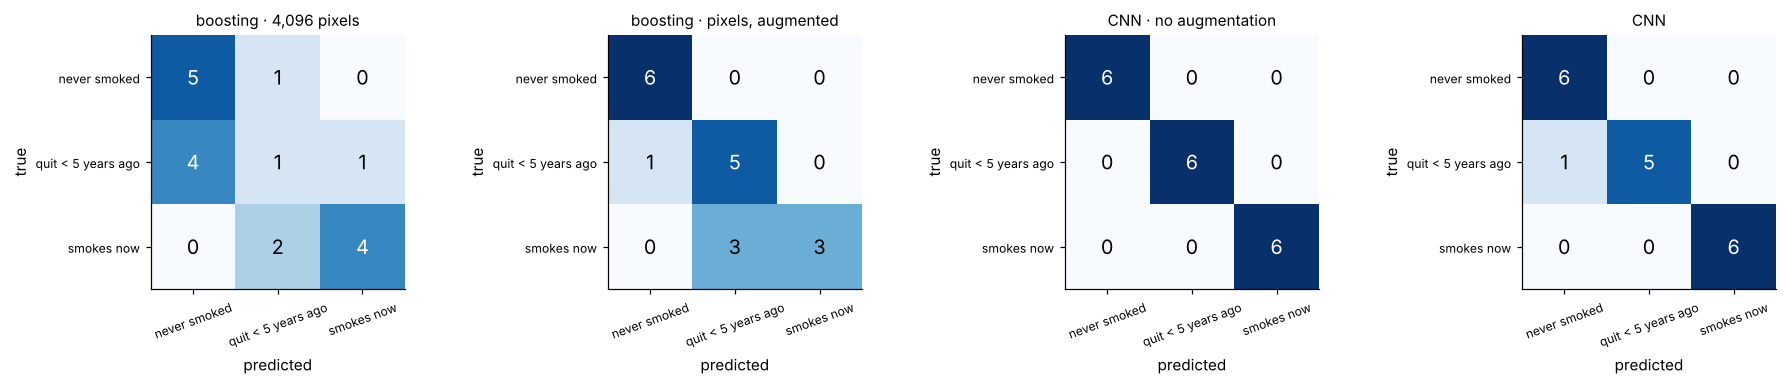

In [15]:
show_confusions(["boosting · 4,096 pixels", "boosting · pixels, augmented", "CNN · no augmentation", "CNN"])

## 5 · Is the difference real? Ten balanced splits
One split of 18 test images can favour either model by chance. We therefore repeat the whole procedure on **ten** different stratified splits (14 + 6 images per class each time) and report the mean and standard deviation of every metric. For the CNN this takes a few minutes.

In [16]:
rep = []; pooled = {}
sss = StratifiedShuffleSplit(n_splits=10, test_size=18, random_state=SEED)
t0 = time.time()
for s, (tr_s, te_s) in enumerate(sss.split(X, y)):
    P = {}
    P["boosting · 4,096 pixels"] = gb_pixels(s).fit(flat(X[tr_s]), y[tr_s]).predict_proba(flat(X[te_s]))
    Xa_s, ya_s = augmented_table(X[tr_s], y[tr_s], seed=s)
    P["boosting · pixels, augmented"] = gb_pixels(s).fit(Xa_s, ya_s).predict_proba(flat(X[te_s]))
    P["CNN · no augmentation"] = predict_cnn(fit_cnn(X[tr_s], y[tr_s], seed=s, use_aug=False)[0], X[te_s])
    P["CNN"] = predict_cnn(fit_cnn(X[tr_s], y[tr_s], seed=s)[0], X[te_s])
    for m, p in P.items():
        rep.append(dict(split=s, **report(m, y[te_s], p)))
        pooled.setdefault(m, []).append((y[te_s], p))
    print(f"split {s}: " + " · ".join(f"{m} {accuracy_score(y[te_s], p.argmax(1)):.2f}" for m, p in P.items()) + f"  ({time.time() - t0:.0f} s)")
rep = pd.DataFrame(rep)
ORDER = ["boosting · 4,096 pixels", "boosting · pixels, augmented", "CNN · no augmentation", "CNN"]
summary = rep.drop(columns="split").groupby("model").agg(["mean", "std"]).reindex(ORDER)
summary.round(2)

split 0: boosting · 4,096 pixels 0.56 · boosting · pixels, augmented 0.67 · CNN · no augmentation 0.94 · CNN 0.94  (58 s)


split 1: boosting · 4,096 pixels 0.22 · boosting · pixels, augmented 0.67 · CNN · no augmentation 0.83 · CNN 0.89  (119 s)


split 2: boosting · 4,096 pixels 0.39 · boosting · pixels, augmented 0.67 · CNN · no augmentation 0.83 · CNN 0.89  (179 s)


split 3: boosting · 4,096 pixels 0.67 · boosting · pixels, augmented 0.72 · CNN · no augmentation 0.89 · CNN 0.94  (239 s)


split 4: boosting · 4,096 pixels 0.39 · boosting · pixels, augmented 0.67 · CNN · no augmentation 0.83 · CNN 1.00  (298 s)


...

split 6: boosting · 4,096 pixels 0.61 · boosting · pixels, augmented 0.50 · CNN · no augmentation 0.72 · CNN 0.83  (418 s)


split 7: boosting · 4,096 pixels 0.33 · boosting · pixels, augmented 0.56 · CNN · no augmentation 0.78 · CNN 0.94  (479 s)


split 8: boosting · 4,096 pixels 0.67 · boosting · pixels, augmented 0.78 · CNN · no augmentation 0.89 · CNN 0.89  (540 s)


split 9: boosting · 4,096 pixels 0.50 · boosting · pixels, augmented 0.67 · CNN · no augmentation 0.83 · CNN 0.78  (602 s)


accuracy       macro_F1       recall_never       recall_former       recall_current       log_loss        \
                                 mean   std     mean   std         mean   std          mean   std           mean   std     mean   std   
model                                                                                                                                   
boosting · 4,096 pixels          0.50  0.16     0.50  0.16         0.57  0.22          0.35  0.18           0.58  0.24     2.23  0.98   
boosting · pixels, augmented     0.66  0.08     0.64  0.09         0.85  0.12          0.47  0.25           0.65  0.17     1.43  0.35   
CNN · no augmentation            0.84  0.06     0.84  0.07         0.85  0.17          0.77  0.22           0.92  0.09     0.43  0.09   
CNN                              0.89  0.07     0.88  0.09         1.00  0.00          0.70  0.25           0.97  0.07     0.36  0.05   

                               AUC        
                              mean   std  
model                                     
boosting · 4,096 pixels       0.69  0.13  
boosting · pixels, augmented  0.82  0.06  
CNN · no augmentation         0.96  0.04  
CNN                           0.99  0.01

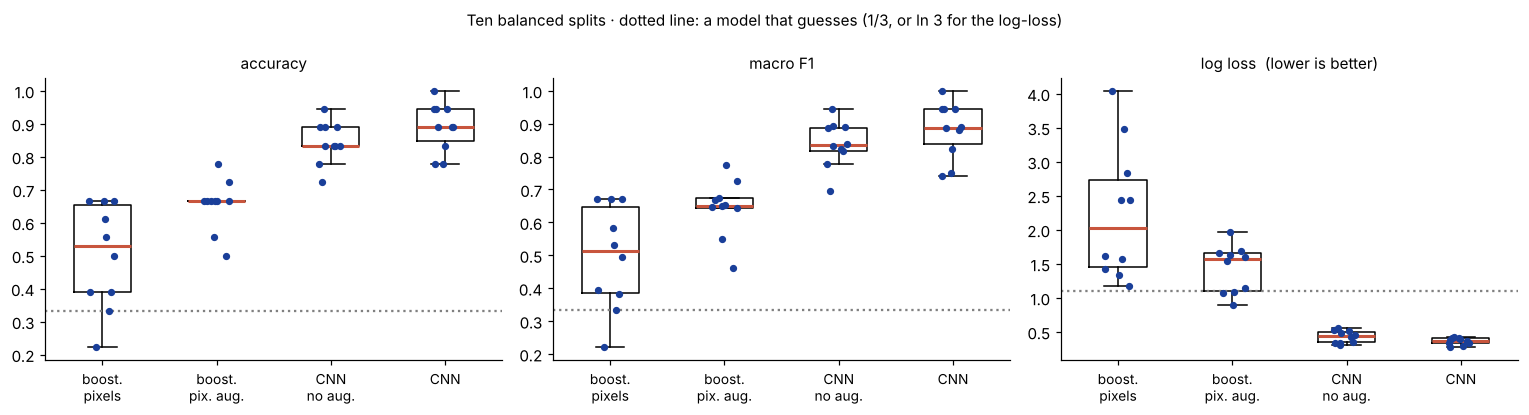

CNN minus boosting on pixels, accuracy: mean +0.39, CNN better in 10 of 10 splits, equal in 0


In [17]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for a, met, ref in zip(axs, ["accuracy", "macro_F1", "log_loss"], [1 / 3, 1 / 3, np.log(3)]):
    data = [rep[rep.model == m][met].values for m in ORDER]
    a.boxplot(data, widths=.5, showfliers=False, medianprops=dict(color="#C8553D", lw=2))
    for k, d_ in enumerate(data): a.scatter(np.full(len(d_), k + 1) + np.random.default_rng(k).uniform(-.12, .12, len(d_)), d_, s=14, color="#1A3F99", zorder=3)
    a.axhline(ref, color="grey", ls=":"); a.set_xticks(range(1, 5), ["boost.\npixels", "boost.\npix. aug.", "CNN\nno aug.", "CNN"], fontsize=9)
    a.set_title(met.replace("_", " ") + ("  (lower is better)" if met == "log_loss" else ""), fontsize=10)
plt.suptitle("Ten balanced splits · dotted line: a model that guesses (1/3, or ln 3 for the log-loss)", fontsize=10); plt.tight_layout(); plt.show()
w = rep.pivot(index="split", columns="model", values="accuracy")
diff = w["CNN"] - w["boosting · 4,096 pixels"]
print(f"CNN minus boosting on pixels, accuracy: mean {diff.mean():+.2f}, CNN better in {(diff > 0).sum()} of 10 splits, equal in {(diff == 0).sum()}")

Pooling the ten test sets gives 180 predictions per model, enough for a stable confusion matrix in percentages of each true class.

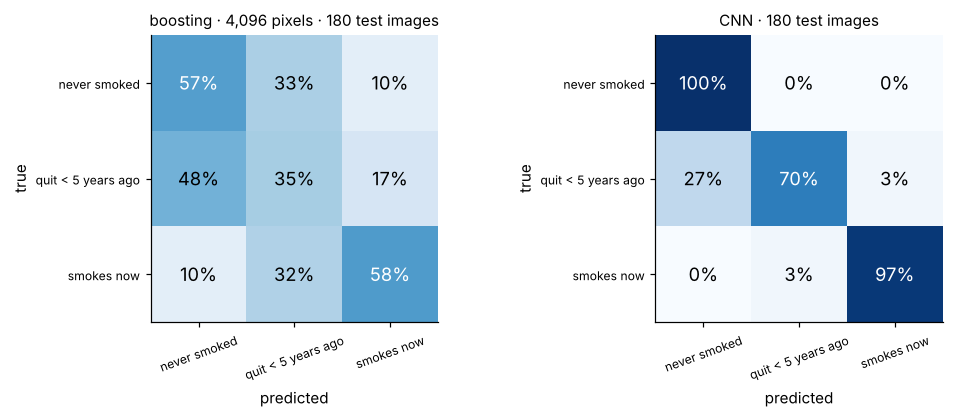

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.9))
for a, m in zip(axs, ["boosting · 4,096 pixels", "CNN"]):
    yt_ = np.concatenate([t for t, _ in pooled[m]]); pr_ = np.concatenate([p for _, p in pooled[m]]).argmax(1)
    cm = confusion_matrix(yt_, pr_, labels=[0, 1, 2], normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): a.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=12, color="white" if cm[i, j] > .5 else "black")
    a.set_xticks(range(3), [NAMES[c] for c in CLASSES], rotation=20, fontsize=8); a.set_yticks(range(3), [NAMES[c] for c in CLASSES], fontsize=8)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{m} · 180 test images", fontsize=10)
plt.tight_layout(); plt.show()

**Interpretation.**
* **Boosting on pixels** classifies about half of the test images correctly (0.50 ± 0.16), above chance (0.33) but far from useful, and it varies strongly from split to split (from 0.22 to 0.67). Its log-loss (about 2.2) lies **above** ln 3 ≈ 1.10, the log-loss of a model that always answers 1/3: when it is wrong, it is confidently wrong. Its AUC of about 0.69 shows that its scores still carry some ranking information, the weak lung-brightness signal of Section 1.2.
* **Augmentation helps boosting, but only part of the way** (about 0.66 accuracy, AUC 0.82). Ten transformed copies of each image tell the trees that the chest moves, so they rely less on single positions. They remain unable to express "a bright spot anywhere in the lung", and the log-loss stays above ln 3.
* **The CNN** reaches about 0.89 accuracy, an AUC of 0.99 and a log-loss of about 0.36, and it beats boosting on pixels in **all ten** splits. In the pooled confusion matrix it never labels a never-smoker as a smoker; its errors concentrate on the middle class, where about a quarter of the recent quitters look like never-smokers. This pattern fits the data: the classes differ in **how many** lesions an image contains, and some quitters carry only three faint nodules.
* **Without augmentation** the CNN loses a little (about 0.84 accuracy, AUC 0.96). The convolution and the global pooling already provide most of the invariance to *where* a lesion sits; augmentation adds invariance to the rotation and scale of the whole chest, which convolutions do not provide by themselves.
* With 18 test images per split the standard deviations are large (about ±0.07 to ±0.16 for accuracy). Only the repetition over ten splits makes the ranking credible; on the main split alone, the CNN without augmentation even looked better than the CNN with it.

## 6 · Why the CNN wins: two experiments

### 6.1 · Where does the network look?
Because the network ends with global average pooling and one linear layer, we can compute exactly how much each position of the image contributes to the score of a class: the *class activation map* (Zhou et al., 2016) multiplies each filter map of the last block by the weight that the linear layer gives this filter for the class, and adds them up.

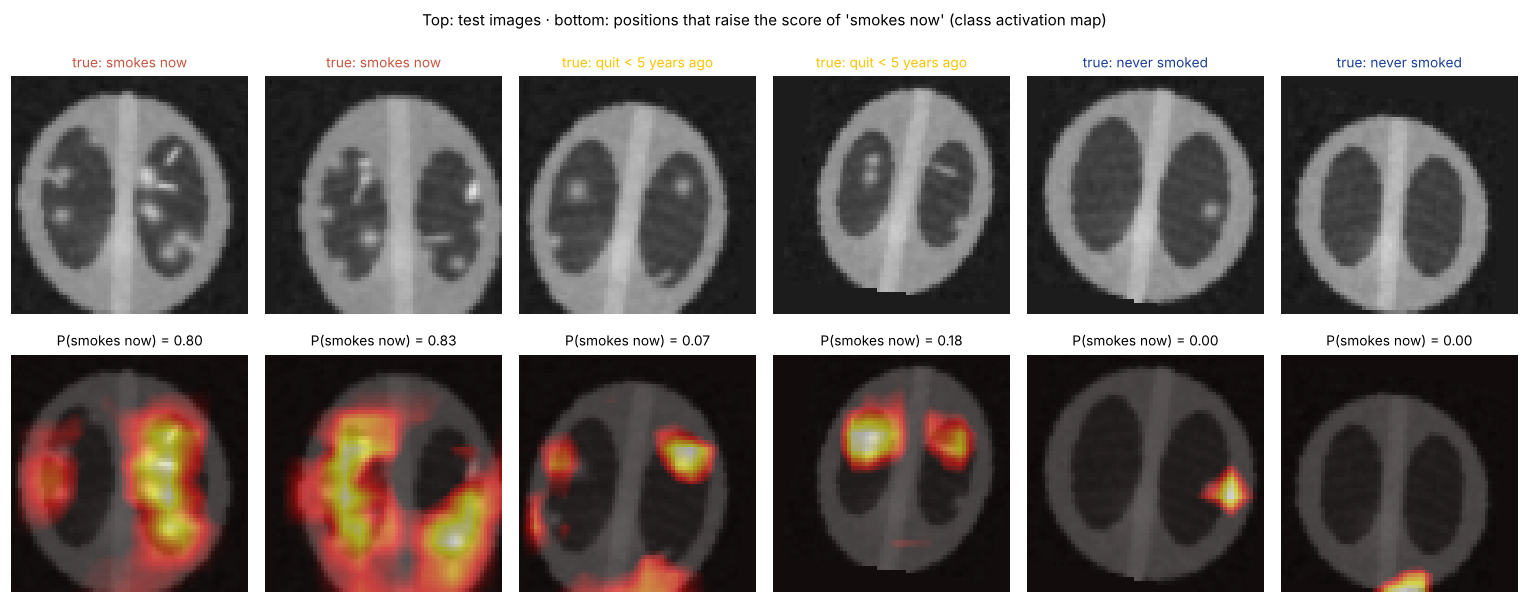

In [19]:
def class_activation_map(model, img, c):
    model.eval()
    with torch.no_grad():
        maps = model.features(torch.tensor(img[None, None]))[0]          # 32 filter maps of 16 x 16
        cam = torch.einsum("k,khw->hw", model.head[-1].weight[c], maps).numpy()
    return ndi.zoom(cam, 64 / cam.shape[0], order=1)

show = [i for k in (2, 1, 0) for i in te[y[te] == k][:2]]
fig, axs = plt.subplots(2, 6, figsize=(14, 5.8))
for j, i in enumerate(show):
    p = predict_cnn(cnn, X[i:i + 1])[0]; cam = class_activation_map(cnn, X[i], 2)
    axs[0, j].imshow(X[i], cmap="gray", vmin=0, vmax=1); axs[0, j].set_title(f"true: {NAMES[CLASSES[y[i]]]}", fontsize=9, color=COL[CLASSES[y[i]]])
    axs[1, j].imshow(X[i], cmap="gray", vmin=0, vmax=1); axs[1, j].imshow(np.maximum(cam, 0), cmap="hot", alpha=.55)
    axs[1, j].set_title(f"P(smokes now) = {p[2]:.2f}", fontsize=9)
for a in axs.ravel(): a.axis("off")
plt.suptitle("Top: test images · bottom: positions that raise the score of 'smokes now' (class activation map)", fontsize=10); plt.tight_layout(); plt.show()

The map lights up on the bright nodules and streaks inside the lungs, at whatever position they occur, and stays dark on ribs, spine and most of the body outline. A few weaker spots on the lower edge of the body show that the network also reacts to some other small bright structures; heatmaps need careful reading, a topic of Lecture 3. Overall, the network has learned the lesion pattern itself, not a set of pixel positions. The next two experiments test this claim without relying on a heatmap.

### 6.2 · Spots or brightness? Implanting lesions into healthy images
A controlled experiment separates the two signals of Section 1.2. We take the six test images of people who **never smoked** and modify them in two ways:
* **spots:** we add 0, 3, 6, 9 or 12 nodules at random positions inside the lungs, with the same size and brightness as in the generator;
* **haze:** we add **the same total amount of brightness**, but spread evenly over the whole lung field, without any spot.

A model that has learned "more round spots mean more smoking" should react to the spots and ignore the haze. A model that has learned "brighter lung pixels mean more smoking" should react to both.

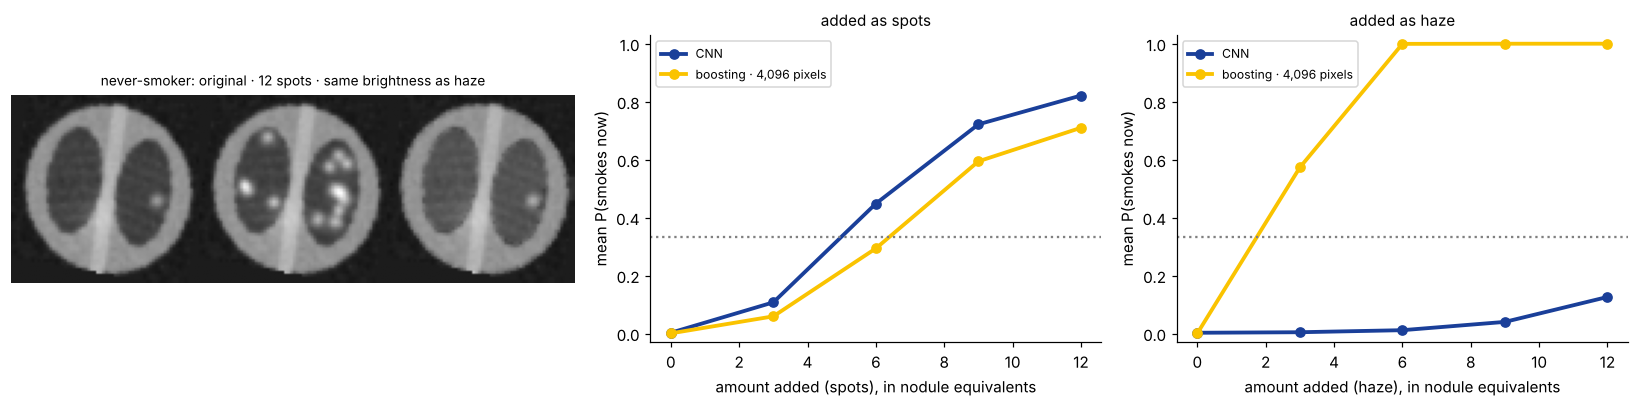

kind   haze                         spots                        
model   CNN boosting · 4,096 pixels   CNN boosting · 4,096 pixels
k                                                                
0      0.00                    0.00  0.00                    0.00
3      0.00                    0.57  0.11                    0.06
6      0.01                    1.00  0.45                    0.29
9      0.04                    1.00  0.72                    0.59
12     0.13                    1.00  0.82                    0.71

In [20]:
def lung_mask(img):
    bg = ndi.median_filter(img, size=9)
    return (bg > 0.17) & (bg < 0.40)                                  # dark, but not air: inside the lungs

def implant(img, k, rng):
    out = img.copy(); ly, lx = np.where(ndi.binary_erosion(lung_mask(img), iterations=2)); yy, xx = np.mgrid[0:64, 0:64]
    for _ in range(k):
        i = rng.integers(len(ly)); r = rng.uniform(1.8, 2.6)
        out += 0.45 * np.exp(-(((yy - ly[i]) / r) ** 2 + ((xx - lx[i]) / r) ** 2))
    return np.clip(out, 0, 1).astype(np.float32)

def haze(img, k, rng):
    out = img.copy(); lung = lung_mask(img)
    out[lung] += k * 0.45 * np.pi * 2.2 ** 2 / lung.sum()           # total brightness of k nodules, spread over the lungs
    return np.clip(out, 0, 1).astype(np.float32)

never_te = te[y[te] == 0]; rows = []
for kind, fn in [("spots", implant), ("haze", haze)]:
    for k in [0, 3, 6, 9, 12]:
        for r_ in range(10):
            rng = np.random.default_rng(100 * k + r_); Xi = np.stack([fn(X[i], k, rng) for i in never_te])
            rows.append(dict(kind=kind, k=k, model="CNN", p=predict_cnn(cnn, Xi)[:, 2].mean()))
            rows.append(dict(kind=kind, k=k, model="boosting · 4,096 pixels", p=gb.predict_proba(flat(Xi))[:, 2].mean()))
imp = pd.DataFrame(rows).groupby(["kind", "model", "k"]).p.mean().reset_index()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
rng = np.random.default_rng(7); i0 = never_te[0]
axs[0].imshow(np.hstack([X[i0], implant(X[i0], 12, rng), haze(X[i0], 12, rng)]), cmap="gray", vmin=0, vmax=1); axs[0].axis("off")
axs[0].set_title("never-smoker: original · 12 spots · same brightness as haze", fontsize=9)
for a, kind in zip(axs[1:], ["spots", "haze"]):
    for m, c in [("CNN", "#1A3F99"), ("boosting · 4,096 pixels", "#FAC300")]:
        d_ = imp[(imp.kind == kind) & (imp.model == m)]; a.plot(d_.k, d_.p, marker="o", lw=2.5, color=c, label=m)
    a.axhline(1 / 3, color="grey", ls=":"); a.set_ylim(-0.03, 1.03); a.set_xlabel(f"amount added ({kind}), in nodule equivalents")
    a.set_ylabel("mean P(smokes now)"); a.set_title(f"added as {kind}", fontsize=10); a.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()
imp.pivot_table(index="k", columns=["kind", "model"], values="p").round(2)

**Interpretation.** Both models react to implanted **spots**: with twelve nodules, both rate the never-smokers as probable current smokers. The **haze** separates them. The CNN barely reacts to evenly spread brightness, because its filters respond to the contrast between a small bright spot and its dark surroundings, not to the overall grey level. Boosting on pixels reacts to the haze even **more** strongly than to the spots: an increase of about 0.015 in the grey level of every lung pixel, invisible to the eye, already pushes its probability of *smokes now* above one half. Boosting has learned "lung pixels brighter than a threshold", which correlates with smoking in our images; the CNN has learned the lesion itself.

### 6.3 · Shifting the whole image by a few pixels
The position of the patient in front of the detector carries no information about smoking. We shift every test image by 2, 4 or 6 pixels to the left, right, up or down and count how often each model changes its predicted class.

In [21]:
rows = []
P0 = {"CNN": predict_cnn(cnn, X[te]), "boosting · 4,096 pixels": gb.predict_proba(flat(X[te]))}
for sh in [2, 4, 6]:
    for dx, dy in [(sh, 0), (-sh, 0), (0, sh), (0, -sh)]:
        Xs = np.stack([ndi.shift(X[i], (dy, dx), order=1, mode="nearest") for i in te])
        P1 = {"CNN": predict_cnn(cnn, Xs), "boosting · 4,096 pixels": gb.predict_proba(flat(Xs))}
        for m in P0:
            rows.append(dict(shift=sh, model=m, changed_class=(P0[m].argmax(1) != P1[m].argmax(1)).mean(),
                             prob_change=np.abs(P0[m] - P1[m]).sum(1).mean() / 2))
shift = pd.DataFrame(rows).groupby(["shift", "model"]).mean().unstack()
shift.style.format("{:.0%}")

**Interpretation.** Shifting an image by two pixels, about 3% of its width, changes the predicted class of roughly a third of the test images for boosting on pixels, and of about half at four or six pixels; its probabilities move by a third to a half of their total mass (`prob_change`, the total variation distance). The CNN changes almost none of its predictions. This is the practical meaning of *translation invariance*: the CNN's answer depends on what the image shows, not on where the patient stood.

The two models do not differ in "intelligence"; they differ in their **inductive bias**, the assumptions built into a model before it sees any data (Lecture 1). Trees assume that each column has a fixed meaning. This holds for tabular data, where column 7 is always "age", and explains why trees remain strong on tables (Grinsztajn et al., 2022). In an image, a pixel has no fixed meaning: pixel 1,873 is lung in one image and rib in the next. Convolutions with shared weights assume instead that the same pattern means the same thing wherever it appears.

## 7 · Can feature engineering rescue gradient boosting?
Gradient boosting fails on **raw pixels**, not on images as such. If we compute columns whose meaning **is** fixed across images, the trees can use them. A classic image-processing tool detects bright spots: the *Laplacian of Gaussian* filter responds strongly at the centre of a round blob of a given size (Lindeberg, 1998). We compute four columns per image:

1. the **number of bright spots** inside the lungs (local maxima of the filter response above a threshold);
2. the **mean filter response** inside the lungs;
3. the **share of bright pixels** inside the lungs;
4. the **standard deviation** of intensities inside the lungs (texture).

### ✏️ Exercise 5 — engineered features
Write `lesion_features(img)` returning the four numbers, using `lung_mask(img)` from Section 6.2, `ndi.gaussian_laplace(img, 1.6)` (take the negative, so bright spots give positive values), `ndi.maximum_filter(..., size=5)` to find local maxima, a response threshold of 0.04 and a brightness threshold of 0.6. Then evaluate gradient boosting (`max_depth=2`, `min_samples_leaf=5`, 100 trees) on these four columns over the same ten splits.

In [22]:
# ✅ SOLUTION
def lesion_features(img):
    lung = lung_mask(img)
    resp = -ndi.gaussian_laplace(img, 1.6)                                  # bright round spots give a large positive response
    peaks = (resp == ndi.maximum_filter(resp, size=5)) & (resp > 0.04) & lung
    return [peaks.sum(), resp[lung].clip(0).mean(), (img[lung] > 0.6).mean(), img[lung].std()]

FEAT = np.array([lesion_features(im) for im in X])
print(pd.DataFrame(FEAT, columns=["spots", "mean response", "bright share", "texture sd"]).groupby(y).mean().set_axis([NAMES[c] for c in CLASSES]).round(3))
for s, (tr_s, te_s) in enumerate(sss.split(X, y)):
    m = HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, max_depth=2, min_samples_leaf=5, random_state=s).fit(FEAT[tr_s], y[tr_s])
    p = m.predict_proba(FEAT[te_s]); rep = pd.concat([rep, pd.DataFrame([dict(split=s, **report("boosting · 4 engineered features", y[te_s], p))])], ignore_index=True)

                    spots  mean response  bright share  texture sd
never smoked          1.6          0.002         0.001       0.060
quit < 5 years ago    2.8          0.003         0.005       0.076
smokes now            4.2          0.005         0.013       0.098


In [23]:
ORDER2 = ORDER[:2] + ["boosting · 4 engineered features"] + ORDER[2:]
final = rep.drop(columns="split").groupby("model").agg(["mean", "std"]).reindex(ORDER2)
show_cols = ["accuracy", "macro_F1", "recall_never", "recall_former", "recall_current", "log_loss", "AUC"]
pd.DataFrame({c: final[c]["mean"].map("{:.2f}".format) + " ± " + final[c]["std"].map("{:.2f}".format) for c in show_cols})

,accuracy,macro_F1,recall_never,recall_former,recall_current,log_loss,AUC
model,,,,,,,
"boosting · 4,096 pixels",0.50 ± 0.16,0.50 ± 0.16,0.57 ± 0.22,0.35 ± 0.18,0.58 ± 0.24,2.23 ± 0.98,0.69 ± 0.13
"boosting · pixels, augmented",0.66 ± 0.08,0.64 ± 0.09,0.85 ± 0.12,0.47 ± 0.25,0.65 ± 0.17,1.43 ± 0.35,0.82 ± 0.06
boosting · 4 engineered features,0.77 ± 0.11,0.77 ± 0.10,0.87 ± 0.13,0.68 ± 0.15,0.77 ± 0.18,1.27 ± 0.93,0.90 ± 0.07
CNN · no augmentation,0.84 ± 0.06,0.84 ± 0.07,0.85 ± 0.17,0.77 ± 0.22,0.92 ± 0.09,0.43 ± 0.09,0.96 ± 0.04
CNN,0.89 ± 0.07,0.88 ± 0.09,1.00 ± 0.00,0.70 ± 0.25,0.97 ± 0.07,0.36 ± 0.05,0.99 ± 0.01


**Interpretation.** Four engineered columns lift gradient boosting from 0.50 to about 0.77 accuracy (AUC 0.90), most of the way towards the CNN (0.89), with a model whose inputs we can name. This confirms the remark that motivated the practical: with the right **representation**, a table works. Three observations limit the lesson:
* Our spot counter is imperfect. The generator places 0–1, 3–5 and 8–12 nodules per class, but the counter finds on average about 1.6, 2.8 and 4.2: it misses touching or faint nodules and counts some ribs and lung edges as spots. Writing a good detector is itself a modelling task, and every choice (filter size 1.6, thresholds 0.04 and 0.6, the lung mask) is a guess that we tuned by eye.
* We could write these features only because we **wrote the generator** and know that the class lives in round bright spots of radius about two pixels. With real radiographs nobody hands us that list; a radiologist's "dirty chest" combines bronchial wall thickening, emphysema and fine opacities (Kirchner et al., 2012), each with its own shape and scale.
* With 42 training rows, boosting on four columns becomes overconfident (log-loss about 1.3, above ln 3), whereas the CNN's probabilities stay informative (0.36).
* The CNN **learned** an equivalent detector from 42 images, and Section 6.1 showed where. In practice the two approaches complement each other: what a network discovers can inspire features that people can audit (Lecture 3).

## 8 · From scores to an underwriting decision
A model alone decides nothing; the insurer must turn probabilities into actions. Consider a triage rule for applications to a supplementary hospital product: **refer the application to a medical underwriter if P(smokes now) ≥ 0.5**; otherwise apply the standard questionnaire. Over the 180 pooled test images we count how often each true class would be referred.

In [24]:
rows = []
for m in ["boosting · 4,096 pixels", "CNN"]:
    yt_ = np.concatenate([t for t, _ in pooled[m]]); pc = np.concatenate([p for _, p in pooled[m]])[:, 2]
    for t in (0.3, 0.5, 0.7):
        rows.append(dict(model=m, rule=f"refer if P(smokes now) ≥ {t}", **{f"referred: {NAMES[c]}": (pc[yt_ == k] >= t).mean() for k, c in enumerate(CLASSES)}))
pd.DataFrame(rows).set_index(["model", "rule"]).style.format("{:.0%}")

A useful rule refers most current smokers and few never-smokers. With the threshold 0.5, the CNN refers about 95% of current smokers and none of the never-smokers; boosting on pixels refers only about 57% of current smokers and already about 10% of never-smokers. In general the threshold sets the trade-off: a lower threshold catches more smokers but sends more never-smokers to an extra examination. Recent quitters are rarely referred by the CNN; whether they should be is a question of how much risk remains after quitting, which the insurer must answer with actuarial evidence, not with this model. Which trade-off is acceptable is a business and ethical decision, not a modelling one: an unnecessary referral costs the applicant time and may deter them, while a missed smoker costs the insurer money through an under-priced risk.

## 9 · Would an insurer be allowed to do this?
* **Data protection.** Radiographs and smoking status are health data, which the revised Swiss Federal Act on Data Protection (nFADP/revDSG, in force since September 2023) classifies as *sensitive personal data* (Art. 5 lit. c). Processing them requires a clear purpose, proportionality and, here, the applicant's **explicit consent** (Art. 6 para. 7).
* **Proportionality and radiation protection.** A radiograph exposes the person to ionising radiation and must be medically justified (Radiological Protection Act, StSG, Art. 8). An insurer could therefore never ask an applicant to undergo an X-ray just to check a questionnaire answer; at most, it could use an existing image that the applicant chooses to share.
* **Asymmetry of errors and fairness.** Lung markings also arise from occupational dust, air pollution, past infections and age. A model trained on smokers versus non-smokers may label a construction worker or an older applicant as a smoker. Before any use, the model would need validation on such groups (Lecture 3).
* **What insurers actually do.** Swiss supplementary insurers rely on the **health questionnaire** and, when needed, on reports from the applicant's physicians. A misrepresentation allows the insurer to terminate the contract (Art. 6 VVG). An image model would at most support a medical underwriter; it would not replace the questionnaire or the physician.

## 10 · Summary
| representation | model | what it can express | result here |
|---|---|---|---|
| 4,096 pixel columns | gradient boosting | "pixel *j* is brighter than *t*", at fixed positions | 0.50 accuracy; fooled by a faint haze and by shifts of 2 pixels |
| same, with 10 augmented copies | gradient boosting | the same, with less reliance on single positions | 0.66 |
| image grid | CNN without augmentation | "a bright spot anywhere" | 0.84 |
| image grid | CNN with augmentation | "how much lesion pattern, anywhere, at any angle" | 0.89; AUC 0.99 |
| 4 engineered columns | gradient boosting | whatever the analyst encoded | 0.77, **if** the analyst knows the pattern |

The general lesson extends Practicals 1–3: neural networks win when the information sits in a **structure** (a shape in a sequence, a pattern in an image) whose **position varies**, and when nobody can easily write that structure down as columns.

## 11 · Reflection questions
1. Section 1.2 showed nearly identical class averages. Design a data set of images in which gradient boosting on pixels **would** work well. What must be true about the position of the signal?
2. Suppose that in a real data set smokers' images came mostly from one hospital whose scanner produces slightly brighter images. Which model would exploit this shortcut, and how would you detect it?
3. The CNN confuses *quit < 5 years* most often with its neighbours. Propose a different loss or output layer that uses the **order** of the three classes (Lecture 1, *Loss*).
4. The insurer can refer 20% of applicants to a medical underwriter. Using the referral table, which threshold and which model would you choose, and what would you tell the applicants who are referred?
5. Our CNN has fewer parameters (about 15,000) than boosting has pixel columns. Why does it nevertheless generalise better from 42 images?

## References
* Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems 35* (Datasets and Benchmarks).
* Ioffe, S., & Szegedy, C. (2015). Batch normalization: accelerating deep network training by reducing internal covariate shift. *Proceedings of the 32nd International Conference on Machine Learning*, 448–456.
* Kirchner, J., Goltz, J. P., Lorenz, F., Obermann, A., Kirchner, E. M., & Kickuth, R. (2012). The "dirty chest" — correlations between chest radiography, multislice CT and tobacco burden. *British Journal of Radiology*, 85(1012), 339–345. https://doi.org/10.1259/bjr/62694750
* LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278–2324.
* Lin, M., Chen, Q., & Yan, S. (2014). Network in network. *International Conference on Learning Representations*. https://arxiv.org/abs/1312.4400
* Lindeberg, T. (1998). Feature detection with automatic scale selection. *International Journal of Computer Vision*, 30(2), 79–116.
* Lu, M. T., Raghu, V. K., Mayrhofer, T., Aerts, H. J. W. L., & Hoffmann, U. (2020). Deep learning using chest radiographs to identify high-risk smokers for lung cancer screening computed tomography. *Annals of Internal Medicine*, 173(9), 704–713. https://doi.org/10.7326/M20-1868
* Shorten, C., & Khoshgoftaar, T. M. (2019). A survey on image data augmentation for deep learning. *Journal of Big Data*, 6, 60.
* Zhou, B., Khosla, A., Lapedriza, A., Oliva, A., & Torralba, A. (2016). Learning deep features for discriminative localization. *IEEE Conference on Computer Vision and Pattern Recognition*, 2921–2929.
* Swiss Federal Act on Insurance Contracts (VVG/LCA), SR 221.229.1, Art. 4–6. Swiss Federal Act on Data Protection (revDSG/nFADP), SR 235.1, Art. 5–6. Radiological Protection Act (StSG/LRaP), SR 814.50, Art. 8. https://www.fedlex.admin.ch